# Ajustar un predictor aprendido con nueve campañas y predecir la décima

**Pregunta:** ¿Qué predice un modelo aprendido para una campaña con la que no se entrenó?

**Nivel 1: Fundamentos** · Requiere: 04-benchmark-protocol/01-three-ways-to-split-the-same-97-blasts · Tiempo de lectura: unos 25 minutos

## Objetivos

Un ingeniero de tronadura que elige un predictor no pregunta qué tan bien recuerda los tiros con los que se construyó. La pregunta es qué dice en la próxima mina, donde nadie ha medido todavía un tamaño de fragmento. Este notebook le hace esa pregunta a los seis predictores aprendidos de la escalera: los ajusta con nueve campañas, esconde la décima y compara lo que dicen con lo que se midió.

Al terminar habrá:

- construido con el motor la partición que deja fuera a Enusa y visto cuánto se diferencian entre sí las diez campañas;
- ajustado gradient boosting con 85 tiros, lo habrá puntuado dentro de sus datos de entrenamiento y en los 12 tiros de Enusa, y habrá leído la brecha;
- repetido el ejercicio con los seis predictores aprendidos y el nulo, y leído cuáles superan a una conjetura constante;
- entendido por qué una varianza explicada bajo cero es un hallazgo y no un error.

## Preparación

Instale los paquetes con los pines exactos de `notebooks/requirements.txt`. El motor es `blastfrag`, publicado en PyPI; los otros paquetes son su base numérica y la biblioteca de gráficos.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

La celda siguiente importa los paquetes, imprime las versiones instaladas para que la salida registre qué motor produjo cada número, y carga los 97 tiros del corpus. También define `Table`, unas pocas líneas que muestran una lista de filas como tabla Markdown en Jupyter y como texto alineado en cualquier otro lugar.

In [1]:
# Importaciones, versiones de los paquetes y el cargador del corpus
from importlib.metadata import version
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")

DERIVED = Path("../../../data/derived")
train = bf.load_training_corpus()
print(len(train), "tiros de", len({b.site for b in train}), "campañas")

class Table:
    """Filas bajo un encabezado, mostradas como tabla Markdown"""

    def __init__(self, header, rows):
        self.header = list(header)
        self.rows = [[str(cell) for cell in row] for row in rows]

    def _repr_markdown_(self):
        lines = ["| " + " | ".join(self.header) + " |", "|" + "---|" * len(self.header)]
        lines += ["| " + " | ".join(row) + " |" for row in self.rows]
        return "\n".join(lines)

    __repr__ = _repr_markdown_

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2
97 tiros de 10 campañas


## Datos

| Fuente | Titular y URL | Clase de licencia | Archivo que lee el notebook |
|---|---|---|---|
| Los 97 tiros, diez campañas | Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 | hechos numéricos reutilizados con cita; el artículo nunca se distribuye | el corpus dentro del paquete `blastfrag` |
| Los seis predictores aprendidos tal como se publicaron | Kulatilake, Hudaverdi y Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (red); Amoako, Jha y Zhong 2022, https://doi.org/10.3390/mining2020013 (vectores de soporte, rbf); Sui et al. 2025, https://doi.org/10.3390/app15031254 (vectores de soporte, polinómico; bosque; boosting; apilamiento) | los métodos se citan, el motor los implementa | `bf.default_arms()` |

No se lee nada más: la comparación del artefacto versionado del caso Enusa con esta ejecución la hacen las pruebas del producto, no este notebook.

## Método

Todos los predictores del motor tienen los mismos dos verbos. `fit(tiros de entrenamiento)` aprende de filas que traen un tamaño medido, y `predict(tiros)` devuelve, para cada tiro, un tamaño medio `x50` en metros o una negativa con su razón. Un predictor de forma cerrada ignora `fit`; uno aprendido hace allí su trabajo. Las entradas son las siete cantidades de diseño y de roca del corpus (las razones S/B, H/B, B/D y T/B, el factor de carga, el tamaño del bloque in situ y el módulo de la roca), y la salida es el tamaño medio de fragmento.

El protocolo es el que respeta la estructura de los datos. Las filas de una campaña comparten macizo, equipo de perforación, suministro de explosivo y operador, así que no son extracciones independientes. Dejar fuera una campaña completa le da al modelo la situación de un usuario: nueve minas de las que aprender y una décima que predecir. El puntaje es `r2_identity`, la varianza explicada respecto de la línea 1:1, `1 - SS_res / SS_tot`. Vale 1 para una predicción perfecta, 0 cuando el predictor no es mejor que la media de las mediciones con que se lo puntúa, y puede ser arbitrariamente negativo. Junto a cada predictor aprendido el notebook puntúa el nulo, que predice para todos los tiros la media de los tamaños de entrenamiento: un modelo que no supera al nulo no aprendió nada que se transfiera.

### Paso 1: la partición, y cuán distintas son las campañas

`leave_one_site_out` entrega una partición por campaña, con los tiros de entrenamiento de las otras nueve y los tiros excluidos de la décima. La celda toma la partición de Enusa y luego tabula los tamaños medidos de cada campaña, para que el lector vea lo que se le pide salvar al modelo.

In [2]:
# Dejar fuera a Enusa: la partición que leave-one-site-out hace para esa campaña
fold = next(split for split in bf.leave_one_site_out(train) if split.test[0].site == "Enusa")
fit_rows = fold.train
test_rows = fold.test
print(fold.protocol, "|", len(fit_rows), "tiros de entrenamiento de", len({b.site for b in fit_rows}),
      "campañas", "|", len(test_rows), "tiros excluidos")
sizes = {}
for blast in train:
    sizes.setdefault(blast.site, []).append(blast.x50_m)
rows = [(site, len(v), f"{min(v):.2f}", f"{np.mean(v):.3f}", f"{max(v):.2f}") for site, v in sorted(sizes.items())]
Table(["campaña", "n", "x50 mín (m)", "x50 medio (m)", "x50 máx (m)"], rows)

leave-out-Enusa | 85 tiros de entrenamiento de 9 campañas | 12 tiros excluidos


| campaña | n | x50 mín (m) | x50 medio (m) | x50 máx (m) |
|---|---|---|---|---|
| Akdaglar | 22 | 0.14 | 0.171 | 0.22 |
| Dongri-Buzurg | 9 | 0.23 | 0.413 | 0.76 |
| Enusa | 12 | 0.26 | 0.396 | 0.64 |
| Miami | 6 | 0.02 | 0.080 | 0.10 |
| Mrica | 11 | 0.13 | 0.166 | 0.21 |
| Murgul | 7 | 0.23 | 0.311 | 0.38 |
| Ozmert | 7 | 0.12 | 0.191 | 0.30 |
| Reocin | 10 | 0.44 | 0.616 | 0.96 |
| Reocin-UG | 6 | 0.51 | 0.593 | 0.69 |
| Soma | 7 | 0.15 | 0.224 | 0.28 |

La celda siguiente dibuja como imagen la tabla de arriba: una columna de puntos por campaña, ordenadas por tamaño medio, con la media como barra negra y Enusa en naranja. Mire cuán separados están los niveles de las campañas comparados con la dispersión dentro de cada una.

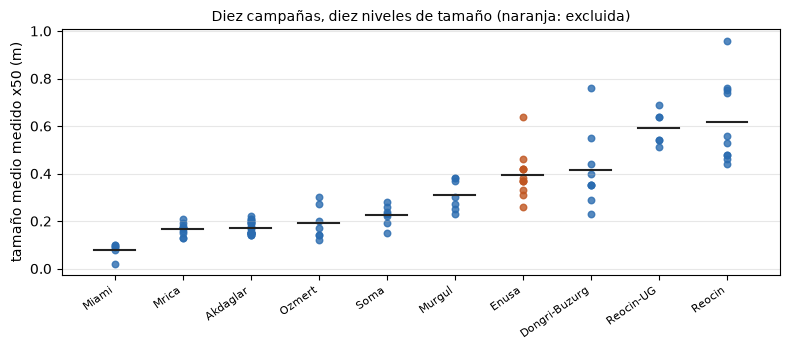

In [3]:
# Tamaño medio medido por campaña; Enusa es la que los modelos nunca ven
order = sorted(sizes, key=lambda site: np.mean(sizes[site]))
fig, ax = plt.subplots(figsize=(8, 3.6))
for k, site in enumerate(order):
    color = "#c05621" if site == "Enusa" else "#2b6cb0"
    ax.scatter(np.full(len(sizes[site]), k), sizes[site], s=22, color=color, alpha=0.8)
    ax.plot([k - 0.3, k + 0.3], [np.mean(sizes[site])] * 2, color="#222", lw=1.5)
ax.set_xticks(range(len(order)), order, rotation=35, ha="right", fontsize=8)
ax.set_ylabel("tamaño medio medido x50 (m)")
ax.set_title("Diez campañas, diez niveles de tamaño (naranja: excluida)", fontsize=10)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

**Qué muestra la figura.** Las diez campañas están en niveles de tamaño muy distintos: los seis tiros de Miami promedian 0,080 m y los diez de Reocin promedian 0,616 m, casi ocho veces más, y dentro de Enusa (naranja) los doce tiros van de 0,26 m a 0,64 m en torno a una media de 0,396 m. **Qué no muestra:** por qué difieren los niveles. La causa es una mezcla de roca, explosivo y método de medición que las siete entradas describen solo en parte. **Qué se sigue:** un modelo que vio nueve de esos niveles debe ubicar el décimo solo con las entradas, y los pasos siguientes miden cuán bien lo hace.

### Paso 2: un predictor aprendido, dentro de la muestra y en la campaña excluida

Gradient boosting es el predictor aprendido más simple de leer: una suma de árboles de regresión pequeños, cada uno corrigiendo el error de la suma anterior (Sui et al. 2025, https://doi.org/10.3390/app15031254). La celda lo ajusta con los 85 tiros de entrenamiento y lo puntúa dos veces: en las filas con que se ajustó y en los 12 tiros de Enusa que nunca vio. La tabla lista las predicciones de Enusa tiro a tiro.

In [4]:
# Ajustar gradient boosting con las nueve campañas y puntuarlo dentro de la muestra y en Enusa
boosting = bf.default_arms()["xgboost"]().fit(fit_rows)
predictions = boosting.predict(test_rows)
in_sample = bf.score(fit_rows, boosting.predict(fit_rows))
held_out = bf.score(test_rows, predictions)
print(f"r2 dentro de la muestra = {in_sample.r2_identity:.3f}   RMSE = {in_sample.rmse_m:.3f} m")
print("desviación estándar de los tamaños medidos en Enusa", f"= {np.std([b.x50_m for b in test_rows]):.3f} m")
print(f"r2 en Enusa = {held_out.r2_identity:.3f}   RMSE = {held_out.rmse_m:.3f} m   sesgo = {held_out.bias_m:+.3f} m")
rows = [(b.blast_id, f"{b.x50_m:.2f}", f"{p.x50_m:.3f}", f"{p.x50_m - b.x50_m:+.3f}") for b,
    p in zip(test_rows, predictions)]
Table(["tiro", "medido (m)", "predicho (m)", "error (m)"], rows)

r2 dentro de la muestra = 0.998   RMSE = 0.008 m
desviación estándar de los tamaños medidos en Enusa = 0.090 m
r2 en Enusa = -0.579   RMSE = 0.114 m   sesgo = +0.067 m


| tiro | medido (m) | predicho (m) | error (m) |
|---|---|---|---|
| En1 | 0.37 | 0.460 | +0.090 |
| En2 | 0.37 | 0.460 | +0.090 |
| En3 | 0.33 | 0.460 | +0.130 |
| En4 | 0.42 | 0.463 | +0.043 |
| En5 | 0.46 | 0.460 | -0.000 |
| En6 | 0.37 | 0.482 | +0.112 |
| En7 | 0.64 | 0.459 | -0.181 |
| En8 | 0.42 | 0.463 | +0.043 |
| En9 | 0.26 | 0.463 | +0.203 |
| En10 | 0.42 | 0.459 | +0.039 |
| En11 | 0.31 | 0.462 | +0.152 |
| En12 | 0.38 | 0.462 | +0.082 |

**Qué muestra la salida.** Dentro de sus datos de entrenamiento el modelo es casi exacto (r2 0,998, RMSE 0,008 m). En Enusa el mismo modelo puntúa r2 -0,579 con un RMSE de 0,114 m y un sesgo de +0,067 m, así que en promedio sobrepredice. La tabla explica la forma de ese error: las doce predicciones están entre 0,459 m y 0,482 m mientras los tamaños medidos van de 0,26 m a 0,64 m. El modelo ubicó a Enusa en un único nivel de tamaño y no distingue sus tiros entre sí, así que es demasiado grueso para En9 (0,26 m medido, 0,463 m predicho) y demasiado fino para En7 (0,64 m medido, 0,459 m predicho). **Qué no muestra:** que el ajuste esté mal. Reproduce las campañas de entrenamiento, que es todo lo que un ajuste garantiza.

### Paso 3: los seis predictores aprendidos, y el nulo

La celda ajusta con las mismas nueve campañas todos los predictores del nivel aprendido: la red de retropropagación de Kulatilake et al. 2012, dos regresores de vectores de soporte, un bosque aleatorio, gradient boosting y un conjunto de apilamiento que combina el bosque y los árboles de boosting. Agrega el nulo, puntúa cada uno dentro de los datos de entrenamiento y en Enusa, y dibuja el error cuadrático medio de ambos, con el error del nulo en Enusa como línea de referencia.

In [5]:
# Ajustar los seis predictores aprendidos y el nulo con las mismas nueve campañas
factories = bf.default_arms()
learned = [name for name, make in factories.items() if make().tier == "learned"]
fitted = {name: factories[name]().fit(fit_rows) for name in learned}
fitted["null"] = bf.NullModel().fit(fit_rows)
scores = {}
for name, model in fitted.items():
    scores[name] = (bf.score(fit_rows, model.predict(fit_rows)), bf.score(test_rows, model.predict(test_rows)))
rows = [(name, f"{a.r2_identity:.3f}", f"{a.rmse_m:.3f}", f"{b.r2_identity:.3f}", f"{b.rmse_m:.3f}",
    f"{b.bias_m:+.3f}")
        for name, (a, b) in scores.items()]
Table(["predictor", "r2 dentro", "RMSE dentro (m)", "r2 Enusa", "RMSE Enusa (m)", "sesgo Enusa (m)"], rows)

| predictor | r2 dentro | RMSE dentro (m) | r2 Enusa | RMSE Enusa (m) | sesgo Enusa (m) |
|---|---|---|---|---|---|
| published-neural-net | 0.998 | 0.009 | -14.163 | 0.352 | +0.334 |
| svr-rbf | 0.939 | 0.048 | -6.644 | 0.250 | +0.206 |
| svr-poly | 0.708 | 0.105 | -37.358 | 0.559 | +0.523 |
| random-forest | 0.974 | 0.031 | -0.482 | 0.110 | +0.056 |
| xgboost | 0.998 | 0.008 | -0.579 | 0.114 | +0.067 |
| stacking | 0.998 | 0.008 | -0.583 | 0.114 | +0.067 |
| null | 0.000 | 0.194 | -1.388 | 0.140 | -0.106 |

La celda siguiente convierte el marcador en barras: el RMSE de cada predictor en las filas con que se ajustó (azul) y en Enusa (naranja), con el error del nulo en Enusa como línea de trazos. La pregunta que hay que hacerle es cuántas barras naranjas se elevan sobre la línea de trazos.

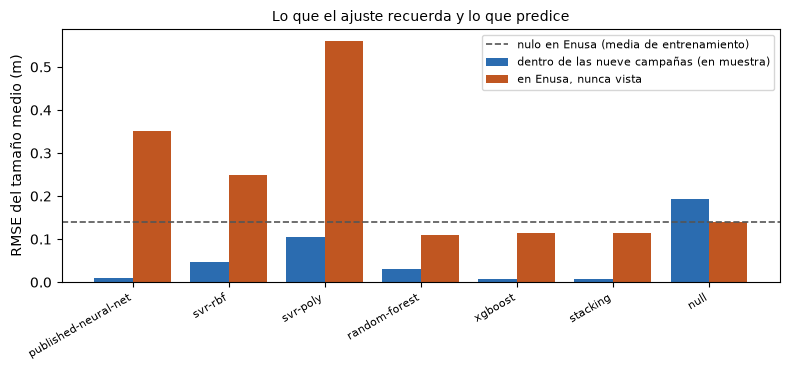

In [6]:
# Error dentro de las campañas de entrenamiento frente al error en la campaña excluida
names = list(scores)
x = np.arange(len(names))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(x - 0.2, [scores[n][0].rmse_m for n in names], 0.4, color="#2b6cb0",
    label="dentro de las nueve campañas (en muestra)")
ax.bar(x + 0.2, [scores[n][1].rmse_m for n in names], 0.4, color="#c05621", label="en Enusa, nunca vista")
ax.axhline(scores["null"][1].rmse_m, color="#555", ls="--", lw=1.2, label="nulo en Enusa (media de entrenamiento)")
ax.set_xticks(x, names, rotation=30, ha="right", fontsize=8)
ax.set_ylabel("RMSE del tamaño medio (m)")
ax.set_title("Lo que el ajuste recuerda y lo que predice", fontsize=10)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

**Qué muestra la figura.** Las barras azules, el error dentro de las nueve campañas de entrenamiento, son todas pequeñas: de 0,008 m para la red y los árboles con boosting a 0,105 m para el regresor de vectores de soporte polinómico. Las barras naranjas, el error en Enusa, son mayores para todos los predictores aprendidos, y para tres de ellos están sobre la línea de trazos, que es el error del nulo en Enusa (0,140 m): la red (0,352 m), el regresor de vectores de soporte radial (0,250 m) y el polinómico (0,559 m) son peores que predecir la media de entrenamiento. El bosque (0,110 m), boosting (0,114 m) y el apilamiento (0,114 m) quedan bajo esa línea. **Qué no muestra:** un orden de los predictores, porque es una campaña de diez.

### Paso 4: dónde pone cada predictor los doce tiros

La última figura grafica, para cada predictor aprendido, sus predicciones de Enusa contra las mediciones. Un predictor perfecto estaría sobre la línea 1:1; uno que no aprendió nada de las diferencias dentro de la campaña dibujaría una banda horizontal.

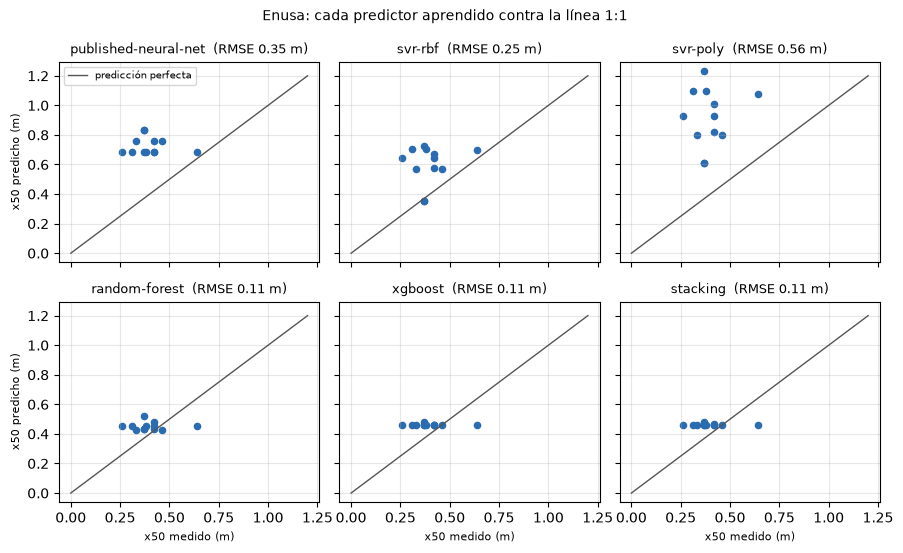

In [7]:
# Tamaño predicho contra medido en Enusa, un panel por predictor aprendido
measured = np.array([b.x50_m for b in test_rows])
fig, axes = plt.subplots(2, 3, figsize=(9, 5.6), sharex=True, sharey=True)
for ax, name in zip(axes.flat, learned):
    predicted = np.array([p.x50_m for p in fitted[name].predict(test_rows)])
    ax.scatter(measured, predicted, s=20, color="#2b6cb0")
    ax.plot([0, 1.2], [0, 1.2], color="#555", lw=1, label="predicción perfecta")
    ax.set_title(f"{name}  (RMSE {scores[name][1].rmse_m:.2f} m)", fontsize=9)
    ax.grid(alpha=0.3)
axes[1, 0].set_xlabel("x50 medido (m)", fontsize=8)
axes[1, 1].set_xlabel("x50 medido (m)", fontsize=8)
axes[1, 2].set_xlabel("x50 medido (m)", fontsize=8)
axes[0, 0].set_ylabel("x50 predicho (m)", fontsize=8)
axes[1, 0].set_ylabel("x50 predicho (m)", fontsize=8)
axes[0, 0].legend(fontsize=7, loc="upper left")
fig.suptitle("Enusa: cada predictor aprendido contra la línea 1:1", fontsize=10)
fig.tight_layout()
plt.show()

**Qué muestra la figura.** Los tres paneles basados en árboles (bosque, boosting, apilamiento) dibujan bandas casi horizontales en torno a 0,46 m, que cruzan la línea 1:1 en la mitad del rango medido: ubican los doce tiros en un tamaño parecido y pierden la dispersión. La red, el regresor de vectores de soporte radial y el polinómico dibujan nubes dispersas muy por encima de la línea, que es el sesgo positivo de +0,334 m, +0,206 m y +0,523 m de la tabla del paso 3. **Qué no muestra:** cómo se comportan estos predictores en las otras nueve campañas, donde el nivel puede ser correcto y los errores distintos. **Qué se sigue:** el error en una campaña nueva lo domina el nivel equivocado, y el nivel es justo lo que nueve campañas ajenas no pueden enseñar.

## Resultados

**Respuesta:** un modelo aprendido predice una campaña que no ha visto más o menos tan bien como una constante, y por lo general peor. En Enusa el mejor de los seis, el bosque aleatorio, puntúa r2 -0,482 con un RMSE de 0,110 m, frente a r2 -1,388 y 0,140 m del nulo; gradient boosting (-0,579, 0,114 m) y el apilamiento (-0,583, 0,114 m) van muy cerca. La red (-14,163, 0,352 m), el regresor de vectores de soporte radial (-6,644, 0,250 m) y el polinómico (-37,358, 0,559 m) son peores que el nulo por un margen amplio. Todos son casi exactos dentro de sus campañas de entrenamiento (r2 entre 0,708 y 0,998), así que la distancia entre 0,998 y -0,579 en boosting es el precio de la transferencia, no un defecto del ajuste.

Por qué los puntajes son tan negativos: los doce tamaños medidos de Enusa tienen una desviación estándar de solo 0,090 m, así que un RMSE de 0,114 m ya excede la dispersión contra la que se mide r2, y un sesgo de varios decímetros, como en la red o en el regresor polinómico, hace colapsar r2. El RMSE y el sesgo son la lectura más justa para una campaña, y dicen lo mismo en metros.

**Qué no muestra esto.** Una campaña es una prueba, y Enusa no es típica. El notebook siguiente repite el ejercicio dejando fuera cada una de las diez campañas por turno y agrupa el resultado, que es el único puntaje con el que el producto encabeza. Tampoco muestra que aprender no pueda ayudar: muestra que estos seis modelos, con 85 filas, no ganan nada en una mina nueva frente a una constante.

## Resumen

- Un predictor aprendido se ajusta con nueve campañas y se le pregunta por la décima; `leave_one_site_out` del motor construye esa partición.
- Dentro de las campañas de entrenamiento todo predictor aprendido es casi exacto (boosting: r2 0,998); en Enusa el mismo boosting puntúa -0,579 y el nulo -1,388.
- Los predictores basados en árboles ubican los doce tiros de Enusa en un solo nivel de tamaño (0,459 m a 0,482 m frente a 0,26 m a 0,64 m medidos); la red y los regresores de vectores de soporte son mucho peores que el nulo.
- Siguiente: el notebook 02 corre los catorce predictores por cada campaña y explica dónde se niega a responder cada uno.

## Referencias

- Kulatilake, Hudaverdi y Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (la red de retropropagación y su conjunto de validación)
- Amoako, Jha y Zhong 2022, https://doi.org/10.3390/mining2020013 (regresión de vectores de soporte, núcleo rbf; la ecuación clásica)
- Sui, Zhou, Zhao, Yang y Zou 2025, https://doi.org/10.3390/app15031254 (vectores de soporte polinómico, bosque, boosting, apilamiento)
- Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 (el corpus y la regresión publicada)
- `blastfrag` 0.4.0, el motor, en PyPI: https://pypi.org/project/blastfrag/